In [ ]:
'''Develop and deploy real-time automated alerting systems for critical business metrics, leveraging anomaly detection models and event-driven architectures to ensure prompt responses to key business events.'''

'Optimize dynamic pricing models by integrating predictive analytics, demand forecasting, and \nprice elasticity modeling to maximize revenue while maintaining customer satisfaction and competitive advantage.'

In [2]:
# import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest

In [3]:
# load dataset
df = pd.read_csv('global_pharmacy_sales_data.csv')
df['date'] = pd.to_datetime(df['date'])
df['revenue'] = df['units_sold'] * df['unit_price']
df.head()

,date,year,month,day,region,country,category,medicine,age_group,units_sold,unit_price,stock_level,expiry_days_remaining,covid_flag,revenue
0,2025-10-12,2025,10,12,Middle East,UAE,Chronic,Amlodipine,0-12,328,45.38,4774,466,0,14884.64
1,2020-09-15,2020,9,15,South Asia,India,Chronic,Amlodipine,26-45,371,75.49,4584,181,1,28006.79
2,2020-02-26,2020,2,26,Middle East,UAE,Vitamin,Vitamin C,0-12,948,22.51,3934,556,1,21339.48
3,2025-11-09,2025,11,9,South Asia,Sri Lanka,Chronic,Amlodipine,0-12,275,63.29,4544,330,0,17404.75
4,2022-04-04,2022,4,4,South America,Argentina,Chronic,Amlodipine,26-45,563,44.28,4284,590,0,24929.64


In [4]:
# aggregate daily business metrics
daily_df = df.groupby('date').agg({
    'revenue': 'sum',
    'units_sold': 'sum',
    'stock_level': 'mean',
    'expiry_days_remaining': 'mean'
}).reset_index().sort_values('date')
daily_df.head()

,date,revenue,units_sold,stock_level,expiry_days_remaining
0,2020-01-01,3069325.55,65568,4196.614458,335.313253
1,2020-01-02,3792212.65,71525,4166.879518,288.867470
2,2020-01-03,2579306.04,53610,4326.777778,347.530864
3,2020-01-04,2674030.68,55388,4332.938272,402.864198
4,2020-01-05,3004000.06,58204,4264.209877,364.172840


In [5]:
# prepare features for anomaly detection
daily_df['revenue_diff'] = daily_df['revenue'].diff().fillna(0)
daily_df['rolling_std'] = daily_df['revenue'].rolling(7, min_periods=1).std().fillna(0)
features = daily_df[['revenue', 'units_sold', 'revenue_diff', 'rolling_std']]
daily_df.head()

,date,revenue,units_sold,stock_level,expiry_days_remaining,revenue_diff,rolling_std
0,2020-01-01,3069325.55,65568,4196.614458,335.313253,0.00,0.000000
1,2020-01-02,3792212.65,71525,4166.879518,288.867470,722887.10,511158.370442
2,2020-01-03,2579306.04,53610,4326.777778,347.530864,-1212906.61,610167.644191
3,2020-01-04,2674030.68,55388,4332.938272,402.864198,94724.64,551466.909993
4,2020-01-05,3004000.06,58204,4264.209877,364.172840,329969.38,477712.274432


In [6]:
# train anomaly detection model
model = IsolationForest(contamination=0.03, random_state=42)
daily_df['anomaly_score'] = model.fit_predict(features)
daily_df['is_anomaly'] = daily_df['anomaly_score'] == -1
daily_df['is_anomaly'].value_counts()

is_anomaly
False    2126
True       66
Name: count, dtype: int64

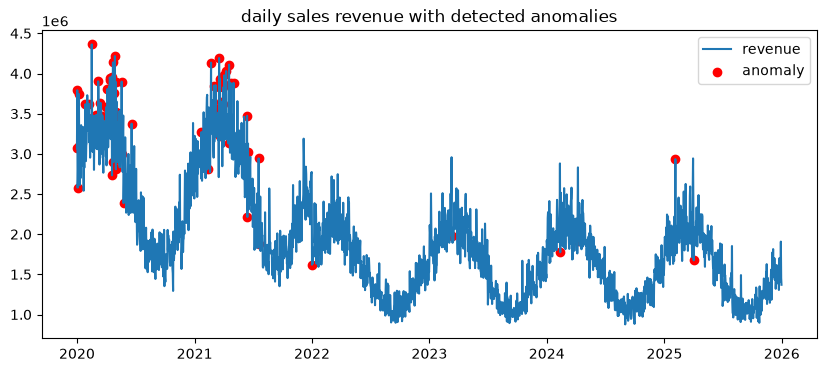

In [7]:
# easy plot of metrics and anomalies
plt.figure(figsize=(10, 4))
plt.plot(daily_df['date'], daily_df['revenue'], label='revenue')
anomalies = daily_df[daily_df['is_anomaly']]
plt.scatter(anomalies['date'], anomalies['revenue'], color='red', label='anomaly')
plt.title('daily sales revenue with detected anomalies')
plt.legend()
plt.show()

In [8]:
# define event driven alert handler
def evaluate_event(event):
    alerts = []
    if event['is_anomaly']:
        alerts.append(f"revenue anomaly: ${event['revenue']:.2f}")
    if event['stock_level'] < 4300:
        alerts.append(f"low stock alert: {event['stock_level']:.0f}")
    if event['expiry_days_remaining'] < 340:
        alerts.append(f"short expiry alert: {event['expiry_days_remaining']:.0f} days")
    return alerts

def trigger_alerts(events):
    event_queue = []
    for _, row in events.iterrows():
        reasons = evaluate_event(row)
        if reasons:
            event_queue.append({
                'date': str(row['date'])[:10],
                'revenue': round(row['revenue'], 2),
                'stock_level': round(row['stock_level'], 1),
                'alerts': reasons
            })
    return event_queue

In [9]:
# simulate real time alerting
sample_events = daily_df[daily_df['is_anomaly']].head(10)
alerts = trigger_alerts(sample_events)
for item in alerts[:5]:
    print(f"date: {item['date']} | revenue: {item['revenue']} | alerts: {item['alerts']}")

date: 2020-01-01 | revenue: 3069325.55 | alerts: ['revenue anomaly: $3069325.55', 'low stock alert: 4197', 'short expiry alert: 335 days']
date: 2020-01-02 | revenue: 3792212.65 | alerts: ['revenue anomaly: $3792212.65', 'low stock alert: 4167', 'short expiry alert: 289 days']
date: 2020-01-03 | revenue: 2579306.04 | alerts: ['revenue anomaly: $2579306.04']
date: 2020-01-07 | revenue: 3744821.56 | alerts: ['revenue anomaly: $3744821.56', 'low stock alert: 4248']
date: 2020-01-08 | revenue: 3101346.35 | alerts: ['revenue anomaly: $3101346.35']


In [10]:
# display alerted events summary
alerts_df = pd.DataFrame(alerts)
alerts_df.head()

,date,revenue,stock_level,alerts
0,2020-01-01,3069325.55,4196.6,"[revenue anomaly: $3069325.55, low stock alert..."
1,2020-01-02,3792212.65,4166.9,"[revenue anomaly: $3792212.65, low stock alert..."
2,2020-01-03,2579306.04,4326.8,[revenue anomaly: $2579306.04]
3,2020-01-07,3744821.56,4247.7,"[revenue anomaly: $3744821.56, low stock alert..."
4,2020-01-08,3101346.35,4320.0,[revenue anomaly: $3101346.35]
